In [2]:
import pandas as pd

In [49]:
df = pd.read_csv(r"D:\Github Repositories\Building-a-Data-Analytics-Agent-using-LLMs\Dataset\ai_job_dataset.csv")
df.head()

,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,benefits_score,company_name,job_description_length
0,AI00001,AI Research Scientist,90376,USD,SE,CT,China,M,China,50,"Tableau, PyTorch, Kubernetes, Linux, NLP",Bachelor,9,Automotive,18-Oct-24,07-Nov-24,5.9,Smart Analytics,1076.0
1,AI00002,AI Software Engineer,61895,USD,EN,CT,Canada,M,Ireland,100,"Deep Learning, AWS, Mathematics, Python, Docker",Master,1,Media,20-Nov-24,11-Jan-25,5.2,TechCorp Inc,1268.0
2,AI00003,AI Specialist,152626,USD,MI,FL,Switzerland,L,South Korea,0,"Kubernetes, Deep Learning, Java, Hadoop, NLP",Associate,2,Education,18-Mar-25,07-Apr-25,9.4,Autonomous Tech,1974.0
3,AI00004,NLP Engineer,80215,USD,SE,FL,India,M,India,50,"Scala, SQL, Linux, Python",PhD,7,Consulting,23-Dec-24,24-Feb-25,8.6,Future Systems,1345.0
4,AI00005,AI Consultant,54624,NaN,EN,PT,France,S,Singapore,100,"MLOps, Java, Tableau, Python",Master,0,Media,15-Apr-25,23-Jun-25,6.6,Advanced Robotics,1989.0


In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
import os
from langchain_groq import ChatGroq

In [46]:
GROQ_API_KEY = os.getenv('GROQ_API_KEY')
os.environ['GROQ_API_KEY'] = GROQ_API_KEY

llm = ChatGroq(
    model="qwen/qwen3-32b",
    temperature=0
)

In [1]:
from pandasai.responses.response_parser import ResponseParser
from IPython.display import Image, display

class PandasDataFrame(ResponseParser):
    def __init__(self, context) -> None:
        super().__init__(context)
    def  format_plot(self, result):
      return display(Image(filename="exports/charts/temp_chart.png"))

Matplotlib is building the font cache; this may take a moment.
c:\Users\hamma\.conda\envs\DataAnalytic_Agent\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [47]:
config={"llm":llm,"response_parser":PandasDataFrame,"max_retries":4,"enable_cache":False}

In [10]:
field_descriptions = {
    'job_id': 'Unique identifier for each job posting',
    'job_title': 'Title or role being advertised',
    'salary_usd': 'Annual salary converted to USD for standardization',
    'salary_currency': 'Original currency in which the salary is offered',
    'experience_level': 'Experience level required (EN=Entry, MI=Mid, SE=Senior, EX=Executive)',
    'employment_type': 'Type of employment contract (FT=Full-time, PT=Part-time, CT=Contract, FL=Freelance)',
    'company_location': 'Country where the hiring company is based',
    'company_size': 'Size of the company (S=Small, M=Medium, L=Large)',
    'employee_residence': 'Country of residence of the employee or job seeker',
    'remote_ratio': 'Percentage of remote work allowed (0=Onsite, 50=Hybrid, 100=Remote)',
    'required_skills': 'List of key technical skills required (comma-separated)',
    'education_required': 'Minimum education level required for the job',
    'years_experience': 'Minimum years of experience required',
    'industry': 'Industry or sector to which the job belongs',
    'posting_date': 'Date when the job was posted (DD-MMM-YYYY)',
    'application_deadline': 'Last date to apply for the job (DD-MMM-YYYY)',
    'benefits_score': 'Score (0–10) reflecting the quality of job benefits',
    'company_name': 'Name of the company offering the job'
}

In [50]:
from pandasai.connectors import PandasConnector
data_df_connector = PandasConnector({"original_df": df},field_descriptions=field_descriptions)

In [51]:
from pandasai import Agent
agent =  Agent(data_df_connector,memory_size=5,
 description="You are a data analysis agent. Your main goal is to help non-technical users analyze data. ",
config=config)

In [52]:
agent.config

Config(save_logs=True, verbose=False, enforce_privacy=False, enable_cache=False, use_error_correction_framework=True, open_charts=True, save_charts=False, save_charts_path='exports/charts', custom_whitelisted_dependencies=[], max_retries=4, lazy_load_connector=True, response_parser=<class '__main__.PandasDataFrame'>, llm=<pandasai.llm.langchain.LangchainLLM object at 0x0000020A81FA9ED0>, data_viz_library='', log_server=None, direct_sql=False, dataframe_serializer=<DataframeSerializerType.CSV: 3>)

In [44]:
agent.chat("How many rows are there?")

15000

In [53]:
agent.chat("How many columns are there?")

19

In [34]:
agent.chat("provide statistics about the data, in a table form")

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_id,15000,15000,AI00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
job_title,15000,20,Machine Learning Researcher,808,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_usd,15000.0,NaN,NaN,NaN,115348.965133,60260.940438,32519.0,70179.75,99705.0,146408.5,399095.0
salary_currency,15000,3,USD,11957,NaN,NaN,NaN,NaN,NaN,NaN,NaN
experience_level,15000,4,MI,3781,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,15000,4,FT,3812,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_location,15000,20,Germany,814,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_size,15000,3,S,5007,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employee_residence,15000,20,Sweden,790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
remote_ratio,15000.0,NaN,NaN,NaN,49.483333,40.812712,0.0,0.0,50.0,100.0,100.0


In [54]:
agent.chat("Show the missing values of data in tabular form")

,column_name,missing_count
0,job_id,0
1,job_title,0
2,salary_usd,0
3,salary_currency,15
4,experience_level,0
5,employment_type,0
6,company_location,0
7,company_size,0
8,employee_residence,0
9,remote_ratio,0


In [55]:
agent.chat("show the value of company location for which currency in null")

,company_location
4,France
113,France
209,France
255,France
9715,France
11604,France
11707,France
11817,France
11900,France
12519,France


In [59]:
agent.chat("what is the currency for company location France except the null?")

'EUR'

In [60]:
agent.chat("impute the missing currency values by EUR, apply the changes to original data")

'Imputed 0 missing currency values with EUR in the dataset.'

In [22]:
agent.chat("drop the job decription characters field from original data")

"The 'job_description_length' field has been dropped from the original data."

In [58]:

agent.start_new_conversation()

In [24]:
agent.chat("Find the jobs for these requirements: Industry: Education, Job Title must be like these Data Analyst, Data Engineer, Data Scientist, Remote: 100, Education: Bachelor, Experience: Entry level")

,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,benefits_score,company_name,job_description_length
2893,AI02894,Data Scientist,129525,USD,EN,PT,Switzerland,L,Finland,100,"Java, PyTorch, Linux, TensorFlow",Bachelor,1,Education,30-Apr-25,13-Jun-25,7.0,Autonomous Tech,NaN
3487,AI03488,Data Analyst,131006,USD,EN,FT,Switzerland,L,Switzerland,100,"Mathematics, Git, Java, Hadoop, Deep Learning",Bachelor,1,Education,23-Jul-24,31-Aug-24,9.3,Algorithmic Solutions,2120.0
9755,AI09756,Data Engineer,34984,USD,EN,FL,India,S,Sweden,100,"NLP, Hadoop, Spark, Java",Bachelor,1,Education,17-Feb-25,29-Apr-25,7.7,Predictive Systems,645.0
11965,AI11966,Data Analyst,54063,USD,EN,FT,China,M,Ireland,100,"Git, NLP, Linux",Bachelor,1,Education,13-Dec-24,17-Feb-25,7.4,Predictive Systems,1725.0


In [25]:
agent.chat("Now there is some change in requirements, the job can be less than 100 remote but then the location must be China and industry can be any. Keep remaining requirements same")

,job_id,job_title,salary_usd,salary_currency,experience_level,employment_type,company_location,company_size,employee_residence,remote_ratio,required_skills,education_required,years_experience,industry,posting_date,application_deadline,benefits_score,company_name,job_description_length
1618,AI01619,Data Scientist,47232,USD,EN,FL,China,M,Switzerland,50,"NLP, AWS, Hadoop, Computer Vision, Kubernetes",Bachelor,1,Real Estate,27-Apr-25,15-May-25,7.6,AI Innovations,1401.0
1647,AI01648,Principal Data Scientist,65161,USD,EN,FT,Ireland,L,Ireland,100,"Docker, NLP, Azure",Bachelor,1,Education,26-Jul-24,09-Aug-24,5.6,TechCorp Inc,2423.0
2893,AI02894,Data Scientist,129525,USD,EN,PT,Switzerland,L,Finland,100,"Java, PyTorch, Linux, TensorFlow",Bachelor,1,Education,30-Apr-25,13-Jun-25,7.0,Autonomous Tech,NaN
3246,AI03247,Data Analyst,48050,USD,EN,FL,China,S,China,50,"GCP, Azure, Kubernetes, Python",Bachelor,0,Healthcare,19-Aug-24,29-Sep-24,6.6,Smart Analytics,610.0
3487,AI03488,Data Analyst,131006,USD,EN,FT,Switzerland,L,Switzerland,100,"Mathematics, Git, Java, Hadoop, Deep Learning",Bachelor,1,Education,23-Jul-24,31-Aug-24,9.3,Algorithmic Solutions,2120.0
8659,AI08660,Principal Data Scientist,44307,USD,EN,PT,China,M,China,50,"Python, TensorFlow, Linux, GCP, Spark",Bachelor,1,Manufacturing,16-Jan-24,15-Mar-24,9.6,Cloud AI Solutions,1913.0
9597,AI09598,Data Engineer,54154,USD,EN,PT,China,M,China,50,"Spark, Scala, Python, Kubernetes",Bachelor,1,Finance,31-Jan-25,05-Mar-25,6.5,Smart Analytics,640.0
9755,AI09756,Data Engineer,34984,USD,EN,FL,India,S,Sweden,100,"NLP, Hadoop, Spark, Java",Bachelor,1,Education,17-Feb-25,29-Apr-25,7.7,Predictive Systems,645.0
11525,AI11526,Principal Data Scientist,55061,USD,EN,CT,China,L,China,0,"Python, TensorFlow, PyTorch",Bachelor,0,Media,20-Jun-24,15-Jul-24,6.1,Cognitive Computing,2011.0
11965,AI11966,Data Analyst,54063,USD,EN,FT,China,M,Ireland,100,"Git, NLP, Linux",Bachelor,1,Education,13-Dec-24,17-Feb-25,7.4,Predictive Systems,1725.0


In [57]:
agent.clear_memory()

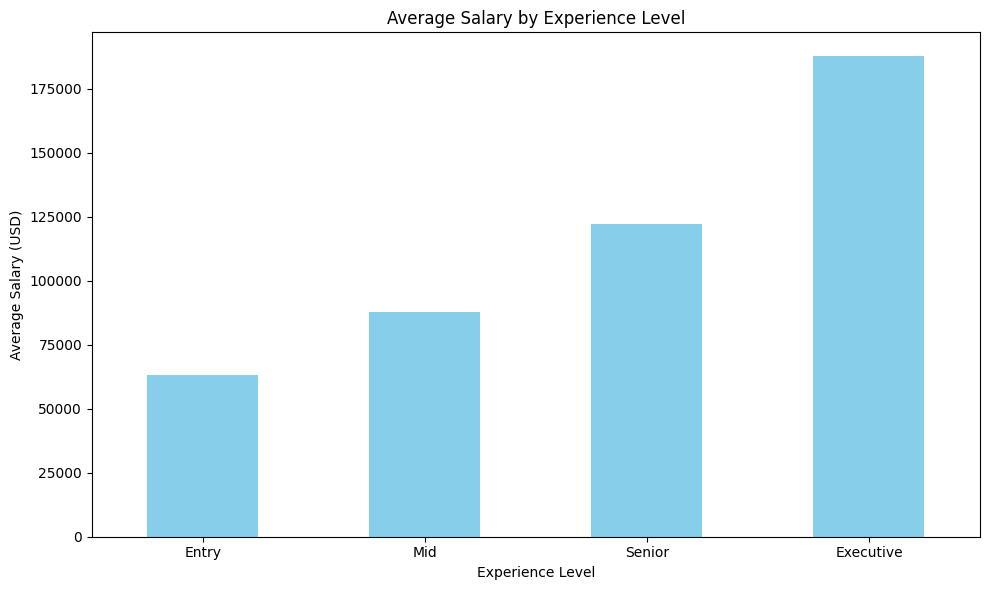

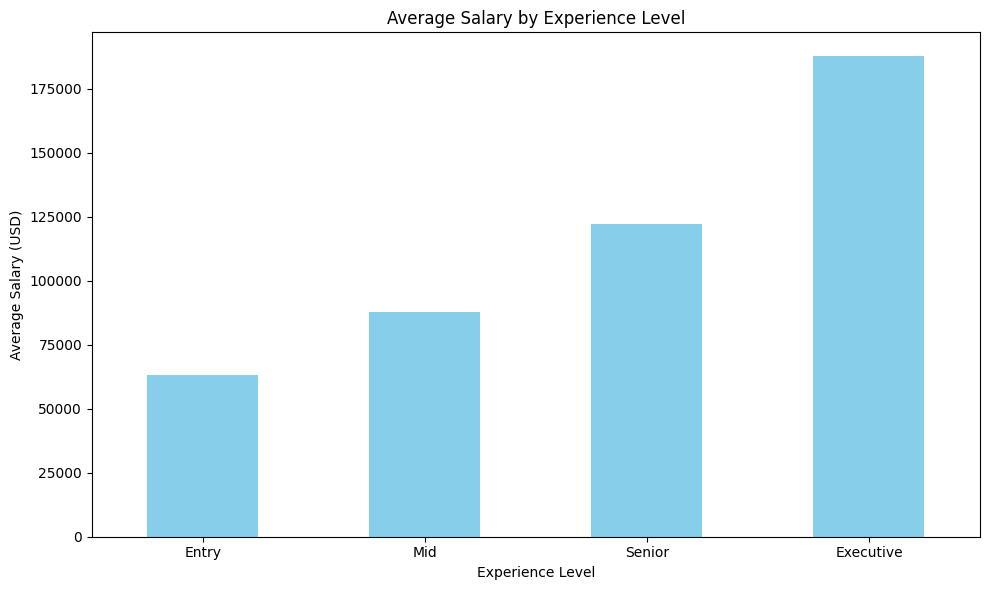

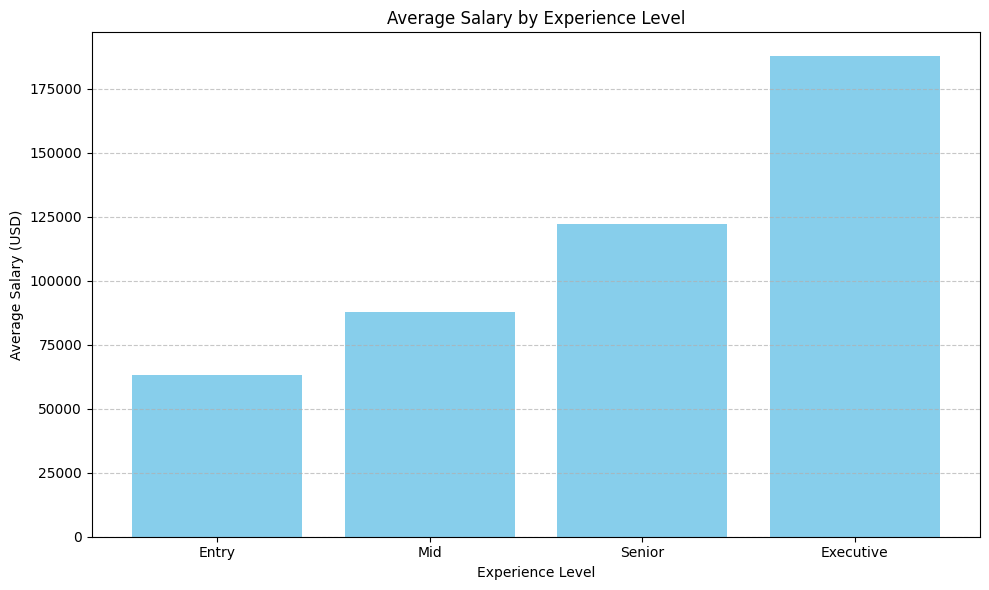

Traceback (most recent call last):
  File "c:\Users\hamma\.conda\envs\DataAnalytic_Agent\lib\site-packages\pandasai\pipelines\chat\generate_chat_pipeline.py", line 335, in run
    ).run(input)
  File "c:\Users\hamma\.conda\envs\DataAnalytic_Agent\lib\site-packages\pandasai\pipelines\pipeline.py", line 137, in run
    raise e
  File "c:\Users\hamma\.conda\envs\DataAnalytic_Agent\lib\site-packages\pandasai\pipelines\pipeline.py", line 101, in run
    step_output = logic.execute(
  File "c:\Users\hamma\.conda\envs\DataAnalytic_Agent\lib\site-packages\pandasai\pipelines\chat\code_execution.py", line 113, in execute
    raise e
  File "c:\Users\hamma\.conda\envs\DataAnalytic_Agent\lib\site-packages\pandasai\pipelines\chat\code_execution.py", line 96, in execute
    if not OutputValidator.validate_result(result):
  File "c:\Users\hamma\.conda\envs\DataAnalytic_Agent\lib\site-packages\pandasai\helpers\output_validator.py", line 73, in validate_result
    raise InvalidOutputValueMismatch(
pand

'Unfortunately, I was not able to answer your question, because of the following error:\n\nResult must be in the format of dictionary of type and value\n'

In [63]:
agent.chat("Show average salary grouped by experience level as a bar chart")

In [62]:
agent.chat("Show average salary grouped by education level as a table")

,education_required,salary_usd
0,Bachelor,115861.629190
1,Master,117171.815902
2,PhD,113728.165579
3,NaN,114605.708058
